# Dimension 2 · Phase 2b — Policy portfolios on a constant 2023 perimeter
## How did Ambiente fare against Seguridad, Educación, Obras Públicas, Transporte…?

**The problem.** Phase 2 compared *organisations* (SAFs) and showed the SAF code is stable.
But "Ministerio de Ambiente" as a SAF (317) is only the ministry's own central administration —
it excludes Parques Nacionales, which was part of the same portfolio. The same is true
everywhere: "Ministerio de Obras Públicas" (SAF 364) excludes Vialidad and ENOHSA;
"Ministerio de Educación" (SAF 330) excludes the university system's own agencies. Comparing
ministries by their central-administration SAF alone would compare bookkeeping units, not
policy areas.

Meanwhile the obvious alternative — compare `jurisdiccion_id` in 2023 with `jurisdiccion_id` in
2025 — is impossible, because **twelve of the twenty-five 2023 jurisdicciones no longer exist**.
Ambiente, Ciencia, Educación, Obras Públicas and Transporte were all dissolved as budget
jurisdictions. There is nothing to compare them *to*.

**The solution used here: the 2023 policy portfolio.**

1. Freeze the organisational chart at **2023**. Each 2023 *jurisdicción* defines a **portfolio** —
   a policy area, and the set of SAFs that made it up.
2. Do not ask "what does the Ministry of X spend in 2025?" (often: it does not exist). Ask
   instead: **"what happened, by 2025, to the money that in 2023 belonged to portfolio X?"**
3. Assign **every peso of 2025 spending back to a 2023 portfolio**, then compare like with like.

This is a constant-perimeter measure anchored on the last congressionally-approved organigram,
which is also the last congressionally-approved budget. It answers the question the paper needs:
not "was this ministry cut?" but "was this *policy area* cut, and cut more than its peers?"

**Scope:** 2025 vs 2023 · `credito_devengado` · Administración Nacional · INDEC CPI annual average.

---
## 1. Setup and data

Same sources as Phase 2 — see `D2_phase2_institutional.ipynb` §2 for full documentation of the
*Presupuesto de gastos y su ejecución detallada (agrupación anual)* files and the INDEC CPI
series. Nothing here needs a credential.

In [1]:
import json
import re
import ssl
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

MASTER_DIR = Path("../processed"); OUT_DIR = Path("../outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
YEARS = [2023, 2025]

SSL_CTX = ssl.create_default_context(); SSL_CTX.check_hostname = False; SSL_CTX.verify_mode = ssl.CERT_NONE
HEADERS = {"User-Agent": "Mozilla/5.0 (academic research; budget analysis)"}
fetch = lambda u, t=300: urllib.request.urlopen(urllib.request.Request(u, headers=HEADERS), context=SSL_CTX, timeout=t).read()

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 46)

MEASURES = ["credito_vigente", "credito_devengado"]
USECOLS = ["jurisdiccion_id", "jurisdiccion_desc", "servicio_id", "servicio_desc",
           "programa_id", "programa_desc", "funcion_id", "funcion_desc"] + MEASURES


def load_credito(year):
    """Read one year from the master extract built by `scripts/00_build_master.py`.

    All parsing — the decimal-comma conversion, the dtype decisions, the FARN
    validation — happens once, in that script. This notebook does not re-parse
    raw CSV, so it cannot drift from the other notebooks. If the master files are
    missing, run:

        python ../scripts/00_build_master.py

    See `../processed/master_manifest.csv` for the provenance and vintage of each
    file, and note that the publisher revises past years.
    """
    for name in (f"master_{year}.parquet", f"master_{year}.csv.gz"):
        path = MASTER_DIR / name
        if path.exists():
            df = (pd.read_parquet(path, columns=USECOLS) if path.suffix == ".parquet"
                  else pd.read_csv(path, usecols=USECOLS, low_memory=False))
            df["anio"] = year
            return df
    raise FileNotFoundError(
        f"no master file for {year} in {MASTER_DIR.resolve()} — "
        "run `python ../scripts/00_build_master.py` first"
    )

D = {y: load_credito(y) for y in YEARS}


def cpi_annual_average():
    url = ("https://apis.datos.gob.ar/series/api/series/?ids=148.3_INIVELNAL_DICI_M_26"
           "&format=json&limit=5000&start_date=2016-12")
    s = pd.DataFrame(json.loads(fetch(url).decode("utf8"))["data"], columns=["fecha", "ipc"])
    s["fecha"] = pd.to_datetime(s.fecha)
    s = s[s.fecha.dt.year.isin(YEARS)]
    assert (s.groupby(s.fecha.dt.year).size() == 12).all(), "incomplete CPI year"
    return s.groupby(s.fecha.dt.year)["ipc"].mean()


CPI = cpi_annual_average()
DEFLATOR = CPI[2025] / CPI[2023]
TOT = {y: D[y].credito_devengado.sum() for y in YEARS}
TOTAL_REAL = (TOT[2025] / DEFLATOR) / TOT[2023] - 1
print(f"CPI annual average — 2023: {CPI[2023]:,.2f} | 2025: {CPI[2025]:,.2f} | deflator: {DEFLATOR:.4f}")
print(f"Administración Nacional, executed: {TOT[2023]:,.0f} → {TOT[2025]:,.0f} millones $  ({TOTAL_REAL:+.1%} real)")

CPI annual average — 2023: 1,975.01 | 2025: 8,966.17 | deflator: 4.5398
Administración Nacional, executed: 38,025,489 → 123,533,955 millones $  (-28.4% real)


---
## 2. Why a naive comparison fails

The 2023 and 2025 organisational charts, side by side:

In [2]:
def jur(y):
    return D[y].groupby(["jurisdiccion_id", "jurisdiccion_desc"])["credito_devengado"].sum().reset_index()


a, b = jur(2023).set_index("jurisdiccion_id"), jur(2025).set_index("jurisdiccion_id")
chart = a.join(b, lsuffix="_2023", rsuffix="_2025", how="outer")
chart["fate"] = ["survives" if pd.notna(x) and pd.notna(y_) else ("DISSOLVED" if pd.isna(y_) else "created")
                 for x, y_ in zip(chart.jurisdiccion_desc_2023, chart.jurisdiccion_desc_2025)]
display(chart[["jurisdiccion_desc_2023", "credito_devengado_2023", "jurisdiccion_desc_2025", "fate"]])
print(f"{(chart.fate=='DISSOLVED').sum()} of {chart.jurisdiccion_desc_2023.notna().sum()} "
      f"2023 jurisdicciones no longer exist in 2025.")

,jurisdiccion_desc_2023,credito_devengado_2023,jurisdiccion_desc_2025,fate
jurisdiccion_id,,,,
1,Poder Legislativo Nacional,2.284178e+05,Poder Legislativo Nacional,survives
5,Poder Judicial de la Nación,5.171939e+05,Poder Judicial de la Nación,survives
10,Ministerio Público,2.044107e+05,Ministerio Público,survives
20,Presidencia de la Nación,1.389003e+06,Presidencia de la Nación,survives
25,Jefatura de Gabinete de Ministros,1.613855e+05,Jefatura de Gabinete de Ministros,survives
30,Ministerio del Interior,4.199665e+05,NaN,DISSOLVED
35,"Ministerio de Relaciones Exteriores, Comer...",1.788362e+05,"Ministerio de Relaciones Exteriores, Comer...",survives
40,Ministerio de Justicia y Derechos Humanos,1.636576e+05,Ministerio de Justicia,survives
41,Ministerio de Seguridad,1.769615e+06,Ministerio de Seguridad Nacional,survives


12 of 25 2023 jurisdicciones no longer exist in 2025.


---
## 3. The crosswalk

Every 2025 row is assigned to exactly one 2023 portfolio, by three rules applied in order.
Each rule is more permissive than the last, and each row records which rule caught it, so the
crosswalk is fully auditable.

| # | Rule | Logic |
|---|---|---|
| 1 | **SAF continuity** | the 2025 SAF code also existed in 2023 → its 2023 jurisdicción. Covers the large majority: SAF codes survive reorganisation (Phase 2 §4.1). |
| 2 | **Programme-name fingerprint** | the SAF is new, but the *programme name* matches a 2023 programme that belonged to exactly one portfolio → that portfolio. This is what tracks functions absorbed into merged structures. |
| 3 | **Documented manual override** | a handful of programmes were renamed on transfer, so rules 1–2 miss them. Listed explicitly below with the 2023 antecedent. |

Anything still unmatched is reported as **UNALLOCATED**, never silently dropped or spread around.

Generic programme names (`Actividades Centrales`, `Actividades Comunes`, …) are excluded from
rule 2: they exist in every SAF and would match everything.

In [3]:
GENERIC = re.compile(r"^(actividades (centrales|comunes)|conduccion y administracion)", re.I)
norm = lambda s: re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(s).lower())).strip()

# ---- rule 1 table: SAF -> 2023 portfolio
SAF_TO_PORTFOLIO = D[2023].groupby("servicio_id")["jurisdiccion_desc"].first().to_dict()

# ---- rule 2 table: unambiguous 2023 programme name -> 2023 portfolio
p23 = D[2023].assign(key=lambda t: t.programa_desc.map(norm))
p23 = p23[~p23.programa_desc.str.match(GENERIC, na=False) & (p23.key.str.len() > 12)]
n_ports = p23.groupby("key")["jurisdiccion_desc"].nunique()
PROG_TO_PORTFOLIO = (p23[p23.key.isin(n_ports[n_ports == 1].index)]
                     .groupby("key")["jurisdiccion_desc"].first().to_dict())
print(f"rule 2 lookup: {len(PROG_TO_PORTFOLIO):,} unambiguous 2023 programme names")

# ---- rule 3: documented manual overrides.
# Each entry names the 2025 (SAF, programme regex) and the **2023 SAF it descends from**. The
# portfolio is then derived from that antecedent, so an override can never be attached to the
# wrong predecessor. 2025 SAF 377 "Infraestructura Económica y Social" merges the former Obras
# Públicas, Hábitat, ENOHSA and Transporte structures; rules 1–2 catch most of it, but these
# programmes were renamed on transfer and are invisible to a name match.
MANUAL_OVERRIDES = [
    # (2025 SAF, regex on 2025 programme name, 2023 antecedent SAF, note)
    (377, r"Politicas de Transporte Terrestre",     327, "was 'Politicas de Movilidad Integral de Transporte'"),
    (377, r"Secretaria de Transporte",              327, "common activities of the transport secretariat"),
    (377, r"Politicas de Transporte Aereo",         327, "air transport policy coordination"),
    (377, r"Fortalecimiento Movilidad Sostenible",  364, "was 'Infraestructura para el Transporte y la Movilidad Sostenible' (Obras Públicas)"),
    (673, r".",                                     672, "Agencia Nac. de Puertos y Navegación succeeds the Ente de la Vía Navegable"),
]
display(pd.DataFrame(MANUAL_OVERRIDES, columns=["SAF 2025", "programme (regex)", "antecedent SAF 2023", "note"])
        .assign(**{"→ portfolio": lambda t: t["antecedent SAF 2023"].map(SAF_TO_PORTFOLIO)}))

rule 2 lookup: 426 unambiguous 2023 programme names


,SAF 2025,programme (regex),antecedent SAF 2023,note,→ portfolio
0,377,Politicas de Transporte Terrestre,327,was 'Politicas de Movilidad Integral de Tr...,Ministerio de Transporte
1,377,Secretaria de Transporte,327,common activities of the transport secreta...,Ministerio de Transporte
2,377,Politicas de Transporte Aereo,327,air transport policy coordination,Ministerio de Transporte
3,377,Fortalecimiento Movilidad Sostenible,364,was 'Infraestructura para el Transporte y ...,Ministerio de Obras Públicas
4,673,.,672,Agencia Nac. de Puertos y Navegación succe...,Ministerio de Transporte


In [4]:
x = D[2025].copy()
x["key"] = x.programa_desc.map(norm)
x["portfolio"] = x.servicio_id.map(SAF_TO_PORTFOLIO)
x["rule"] = x.portfolio.notna().map({True: "1 · SAF continuity", False: pd.NA})

todo = x.portfolio.isna()
x.loc[todo, "portfolio"] = x.loc[todo, "key"].map(PROG_TO_PORTFOLIO)
x.loc[todo & x.portfolio.notna(), "rule"] = "2 · programme fingerprint"

for saf, pattern, ante, _note in MANUAL_OVERRIDES:
    hit = x.portfolio.isna() & (x.servicio_id == saf) & x.programa_desc.str.contains(pattern, case=False, na=False)
    x.loc[hit, ["portfolio", "rule"]] = [SAF_TO_PORTFOLIO[ante], "3 · manual override"]

x["portfolio"] = x.portfolio.fillna("UNALLOCATED")
x["rule"] = x.rule.fillna("unmatched")

cov = x.groupby("rule")["credito_devengado"].sum().sort_values(ascending=False)
display((cov / TOT[2025] * 100).round(3).to_frame("% of 2025 executed budget"))

,% of 2025 executed budget
rule,
1 · SAF continuity,98.903
3 · manual override,0.777
2 · programme fingerprint,0.183
unmatched,0.137


### 3.1 What stays unallocated

Report it rather than hide it. These are genuinely new structures with no 2023 antecedent, so
assigning them to any portfolio would be an invention.

In [5]:
un = (x[x.portfolio == "UNALLOCATED"]
      .groupby(["servicio_id", "servicio_desc", "programa_desc"])["credito_devengado"].sum()
      .sort_values(ascending=False))
display(un[un > 1].to_frame("devengado 2025"))
print(f"unallocated: {un.sum():,.0f} millones $ = {un.sum()/TOT[2025]:.2%} of the 2025 budget")

devengado 2025
servicio_id servicio_desc                                  programa_desc                                                 
377         Infraestructura Económica y Social             Asistencia Financiera a Empresas Publicas        117799.997414
                                                           Actividades Comunes a los Programas vincula...    30029.073838
388         Ministerio de Capital Humano                   Actividades Centrales                             10462.298747
377         Infraestructura Económica y Social             Actividades Comunes a los Programas de la S...     8020.756170
389         Ministerio de Desregulación y Transformació... Actividades Centrales                              2683.222455
388         Ministerio de Capital Humano                   Apoyo al Desarrollo Integral de la Primera ...       51.339347

unallocated: 169,047 millones $ = 0.14% of the 2025 budget


---
## 4. Deliverable 1 — the SAF ledger

Every SAF that existed in 2023, what became of it, and what it spent in each year.

`status` is derived, not asserted:

- **continues** — same SAF code in both years, same name
- **continues (renamed)** — same code, different name. *This column is the budgetary trace of
  institutional downgrading*: SAF 317 goes from "Ministerio de Ambiente y Desarrollo Sostenible"
  to "Ambiente"; SAF 336 from "Ministerio de Ciencia, Tecnología e Innovación" to "Secretaría de
  Innovación, Ciencia y Tecnología".
- **absorbed → SAF n** — code gone; its programmes are executed by another SAF in 2025 (rule 2/3).
  The successor named is the one that took the largest share of its 2023 spending.
- **dissolved** — code gone and no successor carries its programmes.

For absorbed SAFs the 2025 figure is the spending on *its programmes* wherever they now sit, so
the row remains comparable.

In [6]:
s23 = D[2023].groupby("servicio_id").agg(nombre_2023=("servicio_desc", "first"),
                                         jurisdiccion_2023=("jurisdiccion_desc", "first"),
                                         dev_2023=("credito_devengado", "sum"))
s25 = D[2025].groupby("servicio_id").agg(nombre_2025=("servicio_desc", "first"),
                                         jurisdiccion_2025=("jurisdiccion_desc", "first"),
                                         dev_2025=("credito_devengado", "sum"))

# For SAFs that vanished, follow their programme names into 2025.
p23_by_saf = (D[2023].assign(key=lambda t: t.programa_desc.map(norm))
              .pipe(lambda t: t[~t.programa_desc.str.match(GENERIC, na=False)]))
x_keyed = x.assign(key=x.programa_desc.map(norm))

rows = []
for sid, r in s23.iterrows():
    if sid in s25.index:
        n25 = s25.loc[sid]
        status = "continues" if n25.nombre_2025 == r.nombre_2023 else "continues (renamed)"
        dev25, dest, dest_name = n25.dev_2025, sid, n25.nombre_2025
        jur25 = n25.jurisdiccion_2025
    else:
        keys = set(p23_by_saf.loc[p23_by_saf.servicio_id == sid, "key"])
        succ = x_keyed[x_keyed.key.isin(keys)]
        # manual overrides name their 2023 antecedent SAF explicitly, so attach only that SAF's
        for msaf, pattern, ante, _note in MANUAL_OVERRIDES:
            if ante == sid:
                succ = pd.concat([succ, x_keyed[(x_keyed.servicio_id == msaf) &
                                                x_keyed.programa_desc.str.contains(pattern, case=False, na=False)]])
        succ = succ.drop_duplicates()
        dev25 = succ.credito_devengado.sum()
        if len(succ) and dev25 > 0:
            top = succ.groupby(["servicio_id", "servicio_desc"])["credito_devengado"].sum().idxmax()
            dest, dest_name = top
            status = f"absorbed → SAF {dest}"
            jur25 = succ.groupby("servicio_id")["jurisdiccion_desc"].first().get(dest, "")
        else:
            dest, dest_name, jur25, status = pd.NA, "", "", "dissolved"
    rows.append(dict(servicio_id=sid, nombre_2023=r.nombre_2023, jurisdiccion_2023=r.jurisdiccion_2023,
                     dev_2023=r.dev_2023, status=status, saf_2025=dest, nombre_2025=dest_name,
                     jurisdiccion_2025=jur25, dev_2025=dev25))

ledger = pd.DataFrame(rows)
ledger["real_chg"] = (ledger.dev_2025 / DEFLATOR) / ledger.dev_2023 - 1
ledger.loc[ledger.dev_2023 <= 0, "real_chg"] = pd.NA
ledger["RRI_pp"] = (ledger.real_chg - TOTAL_REAL) * 100
ledger["share_2023_%"] = ledger.dev_2023 / TOT[2023] * 100
ledger["share_2025_%"] = ledger.dev_2025 / TOT[2025] * 100
ledger = ledger.sort_values("dev_2023", ascending=False)

ledger.to_csv(OUT_DIR / "ledger_saf_2023_2025.csv", index=False)
print(f"{len(ledger)} SAFs existed in 2023.  Status breakdown:")
display(ledger.status.str.replace(r"→ SAF \d+", "→ other SAF", regex=True).value_counts().to_frame("SAFs"))

131 SAFs existed in 2023.  Status breakdown:


,SAFs
status,
continues,96
continues (renamed),22
absorbed → other SAF,9
dissolved,4


In [7]:
# Full ledger, ordered by 2023 spending.
display(ledger[["servicio_id", "nombre_2023", "jurisdiccion_2023", "dev_2023", "status",
                "saf_2025", "nombre_2025", "jurisdiccion_2025", "dev_2025", "real_chg", "RRI_pp"]]
        .style.format({"dev_2023": "{:,.0f}", "dev_2025": "{:,.0f}",
                       "real_chg": "{:+.1%}", "RRI_pp": "{:+.1f}"}, na_rep="—"))

,servicio_id,nombre_2023,jurisdiccion_2023,dev_2023,status,saf_2025,nombre_2025,jurisdiccion_2025,dev_2025,real_chg,RRI_pp
117,850,Administración Nacional de la Seguridad Social,"Ministerio de Trabajo, Empleo y Seguridad Social","14,753,197",continues,850,Administración Nacional de la Seguridad Social,Ministerio de Capital Humano,"64,268,030",-4.0%,+24.4
65,355,Servicio de la Deuda Pública,Servicio de la Deuda Pública,"3,468,139",continues,355,Servicio de la Deuda Pública,Servicio de la Deuda Pública,"10,352,094",-34.3%,-5.8
66,356,Obligaciones a Cargo del Tesoro,Obligaciones a Cargo del Tesoro,"2,909,723",continues,356,Obligaciones a Cargo del Tesoro,Obligaciones a Cargo del Tesoro,"6,124,229",-53.6%,-25.2
49,330,Ministerio de Educación,Ministerio de Educación,"2,415,507",continues (renamed),330,Secretaría de Educación,Ministerio de Capital Humano,"5,732,849",-47.7%,-19.3
33,311,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,"2,095,110",continues (renamed),311,"Secretaría Nacional de Niñez, Adolescencia y Familia",Ministerio de Capital Humano,"2,646,377",-72.2%,-43.7
48,328,Secretaría de Energía,Ministerio de Economía,"2,062,545",absorbed → SAF 357,357,Ministerio de Economía,Ministerio de Economía,"4,485,365",-52.1%,-23.7
130,917,Agencia Nacional de Discapacidad,Presidencia de la Nación,"1,329,278",continues,917,Agencia Nacional de Discapacidad,Ministerio de Salud,"4,940,076",-18.1%,+10.3
26,250,"Caja de Retiros, Jubilaciones y Pensiones de la Policía Federal Argentina",Ministerio de Seguridad,"767,849",continues,250,"Caja de Retiros, Jubilaciones y Pensiones de la Policía Federal Argentina",Ministerio de Seguridad Nacional,"2,761,886",-20.8%,+7.7
47,327,Ministerio de Transporte,Ministerio de Transporte,"578,232",absorbed → SAF 377,377,Infraestructura Económica y Social,Ministerio de Economía,"931,949",-64.5%,-36.1
91,470,Instituto de Ayuda Financiera para Pago de Retiros y Pensiones Militares,Ministerio de Defensa,"542,553",continues,470,Instituto de Ayuda Financiera para Pago de Retiros y Pensiones Militares,Ministerio de Defensa,"1,977,733",-19.7%,+8.7


---
## 5. Deliverable 2 — policy portfolios compared

Now aggregate to the 2023 portfolio and compare policy areas on a constant perimeter.

In [8]:
port23 = D[2023].groupby("jurisdiccion_desc")["credito_devengado"].sum()
port25 = x.groupby("portfolio")["credito_devengado"].sum()

P = pd.DataFrame({"dev_2023": port23, "dev_2025": port25}).fillna(0.0)
P = P[P.dev_2023 > 0]
P["real_chg"] = (P.dev_2025 / DEFLATOR) / P.dev_2023 - 1
P["RRI_pp"] = (P.real_chg - TOTAL_REAL) * 100
P["share_2023_%"] = P.dev_2023 / TOT[2023] * 100
P["share_2025_%"] = P.dev_2025 / TOT[2025] * 100
P["priority_ratio"] = P["share_2025_%"] / P["share_2023_%"]
P["n_SAF_2023"] = D[2023].groupby("jurisdiccion_desc")["servicio_id"].nunique()
P = P.sort_values("real_chg")

P.to_csv(OUT_DIR / "portfolios_2023_perimeter.csv")
print(f"Whole budget: {TOTAL_REAL:+.1%} real\n")
display(P.style.format({"dev_2023": "{:,.0f}", "dev_2025": "{:,.0f}", "real_chg": "{:+.1%}",
                        "RRI_pp": "{:+.1f}", "share_2023_%": "{:.2f}", "share_2025_%": "{:.2f}",
                        "priority_ratio": "{:.2f}"}))

Whole budget: -28.4% real



,dev_2023,dev_2025,real_chg,RRI_pp,share_2023_%,share_2025_%,priority_ratio,n_SAF_2023
"Ministerio de las Mujeres, Géneros y Diversidad","79,047",0,-100.0%,-71.6,0.21,0.00,0.00,1
Ministerio de Desarrollo Territorial y Hábitat,"296,326","13,126",-99.0%,-70.6,0.78,0.01,0.01,1
Ministerio de Turismo y Deportes,"74,087","63,072",-81.2%,-52.8,0.19,0.05,0.26,2
Ministerio de Obras Públicas,"878,532","824,965",-79.3%,-50.9,2.31,0.67,0.29,6
Ministerio de Desarrollo Social,"2,120,076","2,653,488",-72.4%,-44.0,5.58,2.15,0.39,2
Jefatura de Gabinete de Ministros,"161,385","216,436",-70.5%,-42.0,0.42,0.18,0.41,7
Ministerio de Ambiente y Desarrollo Sostenible,"77,398","126,218",-64.1%,-35.6,0.20,0.10,0.50,2
Ministerio de Transporte,"629,229","1,088,530",-61.9%,-33.5,1.65,0.88,0.53,7
Ministerio de Economía,"2,724,028","5,659,426",-54.2%,-25.8,7.16,4.58,0.64,21
Obligaciones a Cargo del Tesoro,"2,909,723","6,124,229",-53.6%,-25.2,7.65,4.96,0.65,1


### 5.1 The comparison asked for

Ambiente against the peers named by the research team.

In [9]:
FOCUS = ["Ministerio de Ambiente y Desarrollo Sostenible",
         "Ministerio de Ciencia, Tecnología e Innovación",
         "Ministerio de Obras Públicas",
         "Ministerio de Desarrollo Territorial y Hábitat",
         "Ministerio de Transporte",
         "Ministerio de Educación",
         "Ministerio de Salud",
         "Ministerio de Seguridad",
         "Ministerio de Defensa",
         "Ministerio de Economía",
         "Servicio de la Deuda Pública"]
display(P.loc[[f for f in FOCUS if f in P.index]]
        .style.format({"dev_2023": "{:,.0f}", "dev_2025": "{:,.0f}", "real_chg": "{:+.1%}",
                       "RRI_pp": "{:+.1f}", "share_2023_%": "{:.2f}", "share_2025_%": "{:.2f}",
                       "priority_ratio": "{:.2f}"}))

,dev_2023,dev_2025,real_chg,RRI_pp,share_2023_%,share_2025_%,priority_ratio,n_SAF_2023
Ministerio de Ambiente y Desarrollo Sostenible,"77,398","126,218",-64.1%,-35.6,0.20,0.10,0.50,2
"Ministerio de Ciencia, Tecnología e Innovación","315,416","836,759",-41.6%,-13.1,0.83,0.68,0.82,5
Ministerio de Obras Públicas,"878,532","824,965",-79.3%,-50.9,2.31,0.67,0.29,6
Ministerio de Desarrollo Territorial y Hábitat,"296,326","13,126",-99.0%,-70.6,0.78,0.01,0.01,1
Ministerio de Transporte,"629,229","1,088,530",-61.9%,-33.5,1.65,0.88,0.53,7
Ministerio de Educación,"2,419,879","5,748,579",-47.7%,-19.2,6.36,4.65,0.73,3
Ministerio de Salud,"610,398","1,927,219",-30.5%,-2.0,1.61,1.56,0.97,12
Ministerio de Seguridad,"1,769,615","6,195,115",-22.9%,+5.6,4.65,5.01,1.08,6
Ministerio de Defensa,"1,446,436","5,154,109",-21.5%,+6.9,3.80,4.17,1.10,10
Ministerio de Economía,"2,724,028","5,659,426",-54.2%,-25.8,7.16,4.58,0.64,21


### 5.2 How much does the crosswalk matter?

A discipline check. If we had lazily compared *only* the ministry's own central-administration
SAF — the naive approach — how different would the answer be? Large gaps mean the crosswalk is
doing real work and must be documented in the paper; small gaps mean the finding is robust to
the method.

In [10]:
NAIVE_SAF = {"Ministerio de Ambiente y Desarrollo Sostenible": 317,
             "Ministerio de Ciencia, Tecnología e Innovación": 336,
             "Ministerio de Obras Públicas": 364, "Ministerio de Transporte": 327,
             "Ministerio de Educación": 330, "Ministerio de Salud": 310,
             "Ministerio de Seguridad": 343, "Ministerio de Defensa": 375}
naive = []
for port, saf in NAIVE_SAF.items():
    r = ledger[ledger.servicio_id == saf]
    if not len(r):
        continue
    naive.append({"portfolio": port, "central SAF": saf,
                  "naive (SAF only)": r.real_chg.iloc[0],
                  "portfolio (constant perimeter)": P.loc[port, "real_chg"],
                  "gap_pp": (P.loc[port, "real_chg"] - r.real_chg.iloc[0]) * 100})
display(pd.DataFrame(naive).set_index("portfolio")
        .style.format({"naive (SAF only)": "{:+.1%}", "portfolio (constant perimeter)": "{:+.1%}",
                       "gap_pp": "{:+.1f}"}))

,central SAF,naive (SAF only),portfolio (constant perimeter),gap_pp
portfolio,,,,
Ministerio de Ambiente y Desarrollo Sostenible,317,-80.8%,-64.1%,+16.7
"Ministerio de Ciencia, Tecnología e Innovación",336,-55.7%,-41.6%,+14.1
Ministerio de Obras Públicas,364,-63.2%,-79.3%,-16.1
Ministerio de Transporte,327,-64.5%,-61.9%,+2.6
Ministerio de Educación,330,-47.7%,-47.7%,+0.0
Ministerio de Salud,310,-22.5%,-30.5%,-7.9
Ministerio de Seguridad,343,+58.4%,-22.9%,-81.3
Ministerio de Defensa,375,-29.1%,-21.5%,+7.6


---
## 6. Figure

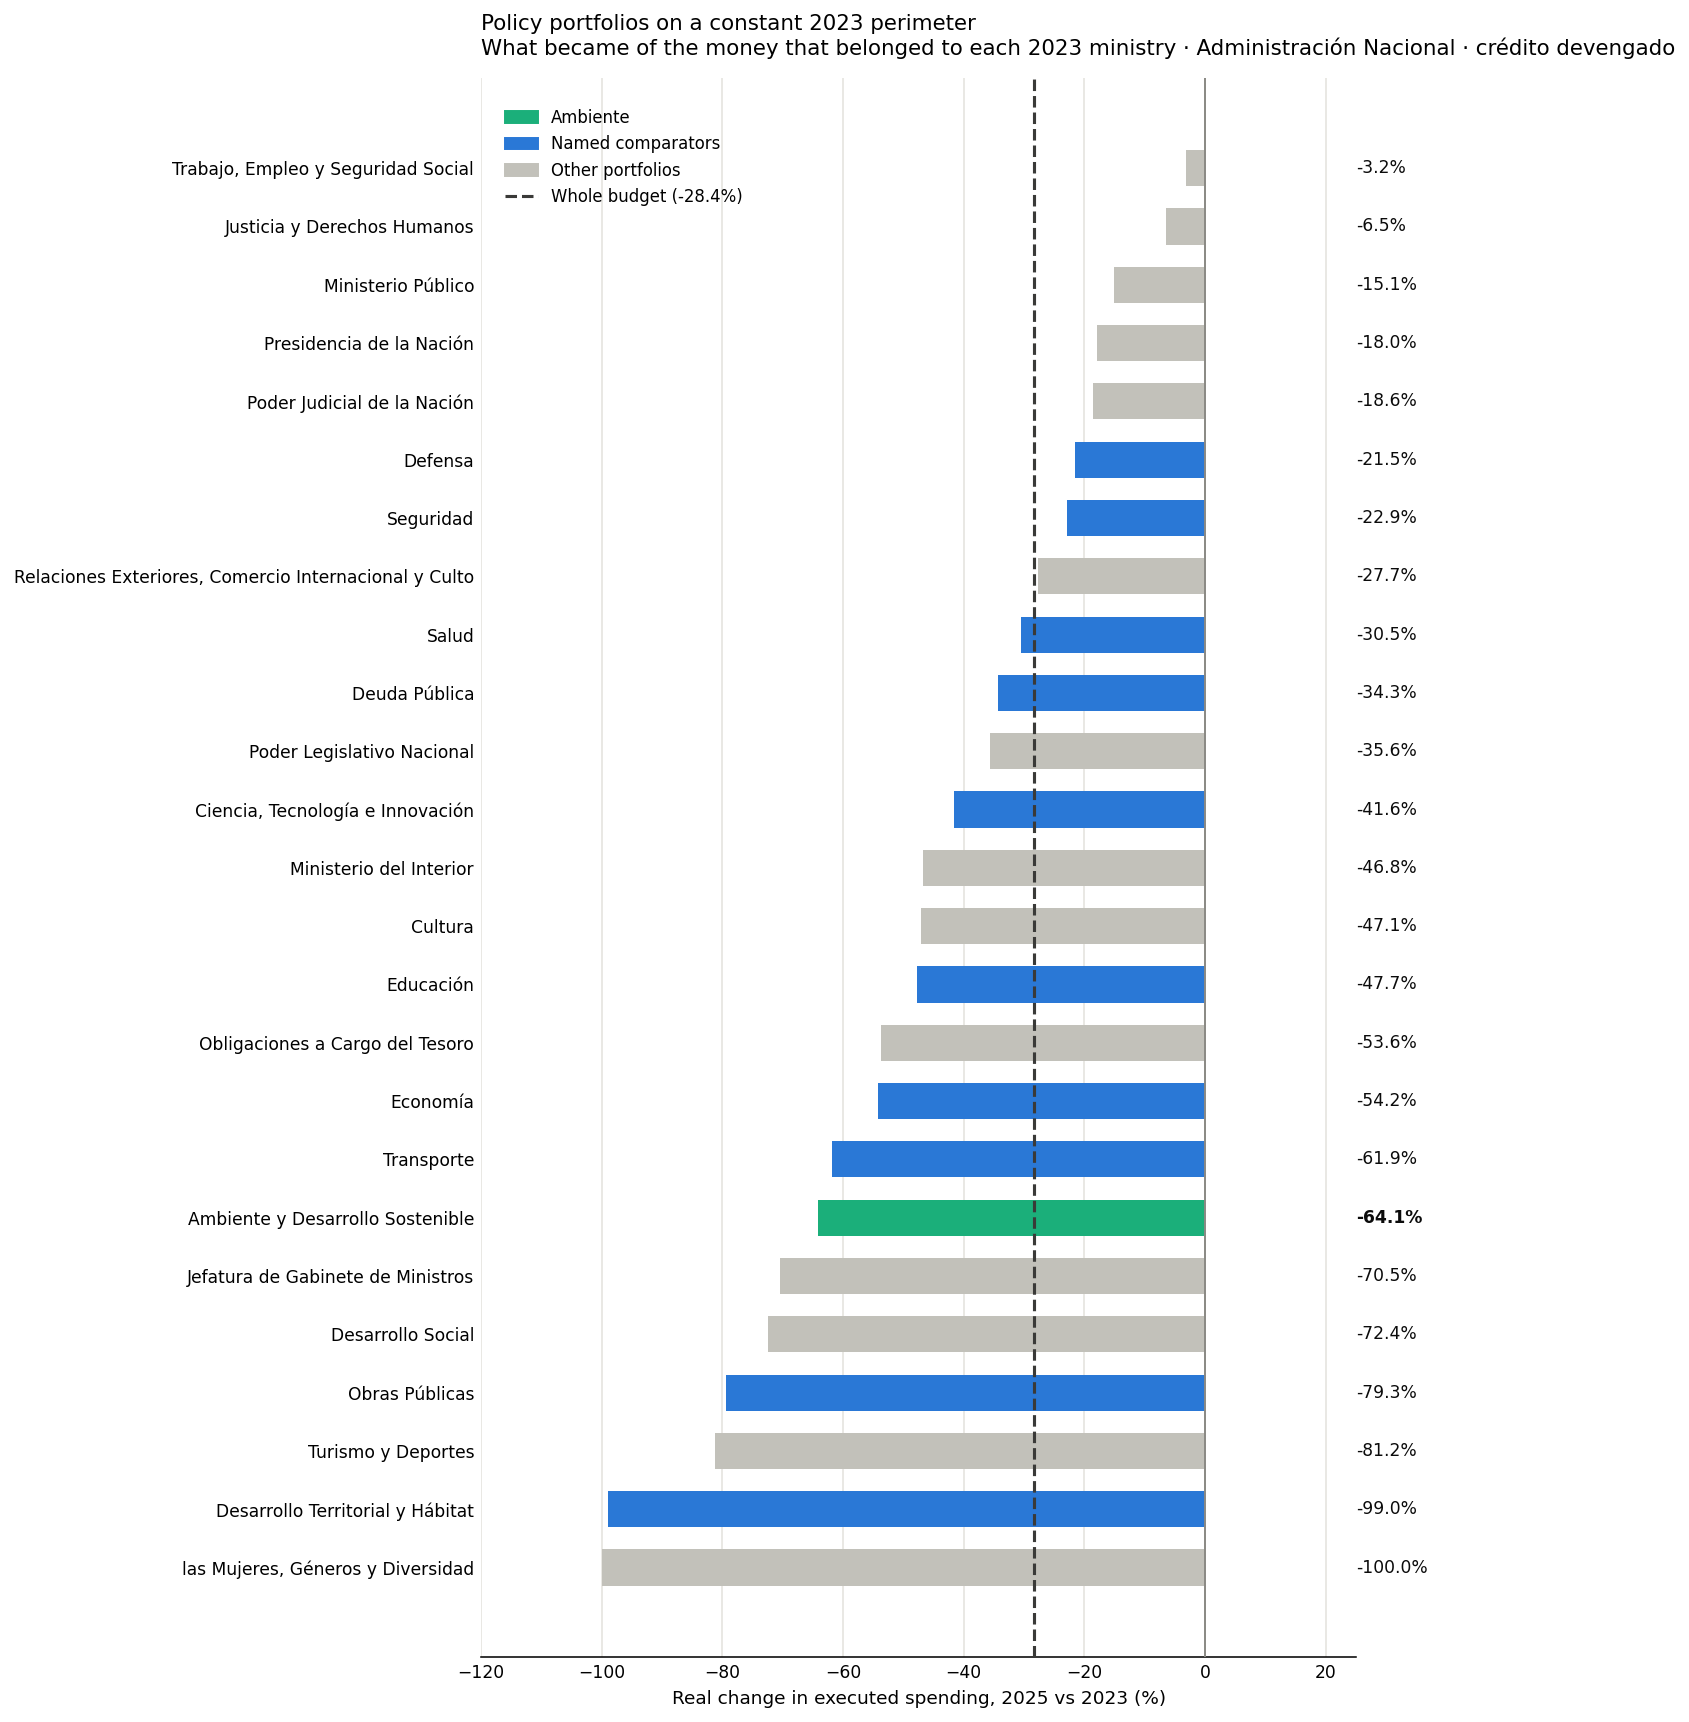

In [11]:
plot = P.copy()
plot.index = [i.replace("Ministerio de ", "").replace("Servicio de la ", "") for i in plot.index]
focus_short = {f.replace("Ministerio de ", "").replace("Servicio de la ", "") for f in FOCUS}
env = "Ambiente y Desarrollo Sostenible"

lo = min(-100, plot.real_chg.min() * 100 - 6)
hi = max(20, plot.real_chg.max() * 100 + 6)
label_x = hi + (hi - lo) * 0.04

fig, ax = plt.subplots(figsize=(10.4, 0.40 * len(plot) + 2.4), dpi=140)
cols = ["#1baf7a" if i == env else ("#2a78d6" if i in focus_short else "#c2c1ba") for i in plot.index]
ax.barh(plot.index, plot.real_chg * 100, color=cols, height=0.62, zorder=3)
ax.axvline(0, color="#8a8984", lw=1, zorder=4)
ax.axvline(TOTAL_REAL * 100, color="#3a3a38", lw=1.6, ls="--", zorder=4)
for y_, (v, name) in enumerate(zip(plot.real_chg * 100, plot.index)):
    ax.text(label_x, y_, f"{v:+.1f}%", va="center", ha="left", fontsize=8.8, color="#0b0b0b",
            fontweight="bold" if name == env else "normal")
ax.set_xlim(lo, label_x); ax.set_xticks(range(int(lo // 20 * 20), int(hi) + 1, 20))
ax.set_xlabel("Real change in executed spending, 2025 vs 2023 (%)", fontsize=9.5)
ax.set_title("Policy portfolios on a constant 2023 perimeter\n"
             "What became of the money that belonged to each 2023 ministry · "
             "Administración Nacional · crédito devengado",
             fontsize=11, loc="left", pad=12)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#1baf7a", "#2a78d6", "#c2c1ba")]
          + [plt.Line2D([0], [0], color="#3a3a38", lw=1.6, ls="--")],
          ["Ambiente", "Named comparators", "Other portfolios", f"Whole budget ({TOTAL_REAL:+.1%})"],
          fontsize=8.5, frameon=False, loc="upper left", bbox_to_anchor=(0.01, 0.99))
ax.grid(axis="x", color="#e3e2dd", zorder=0); ax.set_axisbelow(True)
for sp in ("top", "right", "left"):
    ax.spines[sp].set_visible(False)
ax.tick_params(labelsize=8.8, length=0)
plt.tight_layout()
plt.savefig(OUT_DIR / "fig3_portfolios_real_change.png", dpi=300, bbox_inches="tight")
plt.show()

---
## 7. Consistency check against Phase 1

Portfolio results are built from the institutional classifier; Phase 1's results came from the
functional classifier. They are independent routes through the same data, so where a portfolio
maps cleanly onto a function they should broadly agree.

In [12]:
fn = pd.concat([D[y].assign(anio=y) for y in YEARS]).groupby(["anio", "funcion_desc"])["credito_devengado"].sum().unstack(0)
fn["real_chg"] = (fn[2025] / DEFLATOR) / fn[2023] - 1
pairs = [("Ministerio de Ambiente y Desarrollo Sostenible", "Ecología y Desarrollo Sostenible"),
         ("Ministerio de Ciencia, Tecnología e Innovación", "Ciencia, Tecnología e Innovación"),
         ("Ministerio de Educación", "Educación y Cultura"),
         ("Ministerio de Transporte", "Transporte"),
         ("Ministerio de Salud", "Salud")]
display(pd.DataFrame([{"portfolio": p, "portfolio real chg": P.loc[p, "real_chg"],
                       "función": f, "función real chg": fn.loc[f, "real_chg"],
                       "gap_pp": (P.loc[p, "real_chg"] - fn.loc[f, "real_chg"]) * 100}
                      for p, f in pairs]).set_index("portfolio")
        .style.format({"portfolio real chg": "{:+.1%}", "función real chg": "{:+.1%}", "gap_pp": "{:+.1f}"}))

,portfolio real chg,función,función real chg,gap_pp
portfolio,,,,
Ministerio de Ambiente y Desarrollo Sostenible,-64.1%,Ecología y Desarrollo Sostenible,-64.7%,+0.6
"Ministerio de Ciencia, Tecnología e Innovación",-41.6%,"Ciencia, Tecnología e Innovación",-43.9%,+2.4
Ministerio de Educación,-47.7%,Educación y Cultura,-47.2%,-0.5
Ministerio de Transporte,-61.9%,Transporte,-58.5%,-3.4
Ministerio de Salud,-30.5%,Salud,+11.8%,-42.3


The two classifiers are *not* expected to coincide exactly — a ministry's portfolio contains
spending booked to several functions, and a function draws on several ministries. Divergence is
informative rather than erroneous: it locates where a policy area's spending was relabelled
rather than removed.

---
## 8. Limits of this method — state these in the paper

1. **The portfolio is a 2023 construct.** It answers "what happened to the money that belonged
   to area X in 2023", not "what does area X spend today". Those are different questions; this
   one is the right one for measuring retrenchment, but it should be named as such.
2. **Rule 2 assumes programme names are meaningful identifiers.** They usually are, but a
   renamed programme is invisible to it — which is why rule 3 exists and why every override is
   listed with its 2023 antecedent rather than applied silently.
3. **Absorption is not always clean.** When a merged SAF takes programmes from several
   portfolios, this method splits the successor's spending by programme, which is right when
   programmes stayed intact and approximate when they were themselves merged.
4. **Around 0.14% of 2025 spending stays unallocated**, in genuinely new structures with no 2023
   antecedent. It is reported, not spread.
5. **`Obligaciones a Cargo del Tesoro` behaves differently from a ministry** — it is a residual
   financing vehicle, so its movements reflect accounting decisions as much as policy.

### Sources
See `D2_phase2_institutional.ipynb` §9. Same two sources: Presupuesto Abierto expenditure
microdata (DGSIAF, CC-BY 4.0) and the INDEC CPI via `apis.datos.gob.ar`.